['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)'] ['setosa' 'versicolor' 'virginica']
120 30
Models Predictions: 1 1 2 2
True type of Iris: 1 1 2 2
Accuracy score; 1.0 or 100.0 %
Confusion matrix: [[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


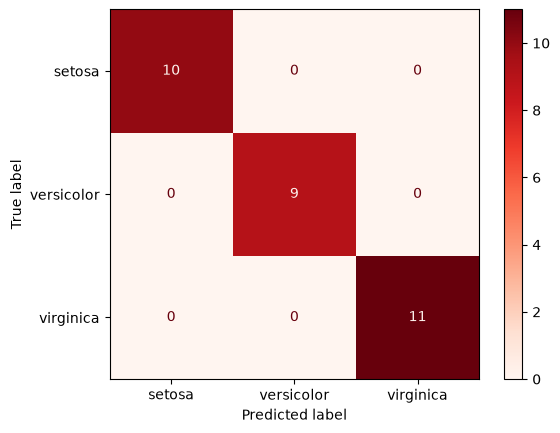

In [39]:
#Iris dataset 80/20 split Decision Tree

import os
import matplotlib.pyplot as plt
#Downloading dataset and splitting it up.

from sklearn.datasets import load_iris
iris = load_iris() # loads iris data set into variable

X = iris.data # all units in cm (feature scaling not neccesarilly required)
y = iris.target

# splits up the data set into two variables one containing the feature lengths and one containing the type of iris.
print(iris.feature_names,iris.target_names) # print to check categories are correct

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = 42) 
# Split dataset into train and test sections with a 80/20 split and assigns them to new varaibles. random_state there for reproducability)
print(len(y_train),len(y_test)) # Testing split worked correctly

#Creating and training model

from sklearn.tree import DecisionTreeClassifier
Model = DecisionTreeClassifier(random_state = 42) # Created Decision Tree Classifier model with standard hyperparameters
#random_state for reproducability again

Model.fit(X_train,y_train) # training model

# Testing model

y_pred = Model.predict(X_test) # uses training and new test data to make predicitons for that data 
#Array of 30 entries 0,1,2 with 0 = Setosa, 1 = Veriscolour, 2 = Virginica.

print("Models Predictions:", y_pred[4], y_pred[9], y_pred[21],y_pred[27])
print("True type of Iris:", y_test[4], y_test[9], y_test[21],y_test[27])
# Inspecting to get a rough idea of how the model is doing. Chose a few random entries for this.

# Checking accuracy

from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test,y_pred) # Checking accuracy of models predictions vs true species
print("Accuracy score;",accuracy,"or", 100*accuracy,"%")

#Confusion matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
confusion_matrix_score = confusion_matrix(y_test,y_pred) # Creating confusion  matrix
print ("Confusion matrix:", confusion_matrix_score)




# Assigning the correct path to output folder
output_folder = r"C:\Users\adamr\OneDrive\Documents\iris-classifier\outputs"


# Plot the confusion matrix with the species labeled
display = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix_score, display_labels=iris.target_names)
display.plot(cmap="Reds")

# Save the confusion matrix as a PNG in the output folder
output_path = os.path.join(output_folder, "confusion_matrix.png")

plt.savefig(output_path, dpi=300,)


plt.show() # Shows the confusion matrix


The Accuracy test showed the AI got identified every Iris flower correctly. The confusion matrix gives a greater level of detail to this, showing it correctly identified the 10 Setosa flowers, the 9 Versicolor flowers and the 11 Virginca flowers. It also showed that in our test set we had slightly more Virginca flowers and slightly fewer Versicolor flowers.